<a href="https://colab.research.google.com/github/Shemuel-bot/AI-ball-notebooks/blob/main/Hash_trainer_lowmem_fast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Ball — Local, Slot-Conditioned Hash Search

This version keeps the machine **single-stage**: each ball still performs exactly one
hash lookup and then reads the emitted string from the deflector table.

The training hash is changed to make generalization possible without layering:

- **Locality:** a ball's address depends only on a configurable neighborhood around it.
- **Relative-position sharing:** the same `(relative offset, token)` feature reuses one
  hash coefficient at every absolute position.
- **Slot separation:** each ball position gets its own bucket region, so a digit emitted
  by one output slot cannot collide with a different slot's meaning.
- **Reuse-aware search:** primary class-purity/CE remains the objective; ties prefer using
  the same class/bucket pair repeatedly instead of creating fresh buckets.
- **Multi-start training:** several independent discrete searches are tried and the best
  training solution is kept.

The physical simulator is unchanged in spirit: `travel -> one lookup -> walk`.
No input-reading layers are added.


In [ ]:
import random

def generate_tiny_cases(num_cases=1000):
    cases = []

    # Define category generators or weights
    # We will cycle through or randomly sample equation types to build exactly `num_cases`

    for i in range(num_cases):
        category = i % 10  # Distribute across 10 different equation types

        if category == 0:
            # 1. Linear Equations (ax + b = c)
            a = random.randint(2, 90)
            b = random.randint(1, 200)
            x = random.randint(-10, 200)
            c = a * x + b
            prompt = f"Solve for x: {a}x + {b} = {c}"
            answer = f"Subtract {b} from both sides to get {a}x = {a*x}, then divide by {a} to find x = {x}."

        elif category == 1:
            # 2. Two-step / Distribution Linear Equations
            a = random.randint(2, 50)
            x = random.randint(-5, 105)
            b = random.randint(1, 100)
            c_val = a * (x + b)
            prompt = f"Solve for x: {a}(x + {b}) = {c_val}"
            answer = f"Divide both sides by {a} to get x + {b} = {c_val//a}, then subtract {b} to find x = {x}."

        elif category == 2:
            # 3. Quadratic Equations (Factorable: (x - r1)(x - r2) = 0)
            r1 = random.randint(-80, 80)
            r2 = random.randint(-80, 80)
            while r1 == r2:
                r2 = random.randint(-80, 80)
            b_coeff = -(r1 + r2)
            c_coeff = r1 * r2
            sign_b = f"+ {b_coeff}x" if b_coeff >= 0 else f"- {abs(b_coeff)}x"
            sign_c = f"+ {c_coeff}" if c_coeff >= 0 else f"- {abs(c_coeff)}"
            prompt = f"Solve for x: x^2 {sign_b} {sign_c} = 0"
            answer = f"Factor the quadratic to get (x - {r1})(x - {r2}) = 0, yielding the solutions x = {r1} and x = {r2}."

        elif category == 3:
            # 4. Exponential Equations (b^x = c)
            base = random.choice([i for i in range(100)])
            x = random.randint(1, 40)
            val = base ** x
            prompt = f"Solve for x: {base}^x = {val}"
            answer = f"Since {val} = {base}^{x}, equating exponents gives x = {x}."

        elif category == 4:
            # 5. Logarithmic Equations (log_b(x) = c)
            base = random.choice([i for i in range(100)])
            x_val = random.randint(1, 50)
            res = base ** x_val
            prompt = f"Solve for x: log_{base}(x) = {x_val}"
            answer = f"Convert to exponential form: x = {base}^{x_val} = {res}."

        elif category == 5:
            # 6. Absolute Value Equations (|ax + b| = c)
            a = random.randint(1, 40)
            b = random.randint(-50, 50)
            x = random.randint(1, 100)
            c = abs(a * x + b)
            sign_b = f"+ {b}" if b >= 0 else f"- {abs(b)}"
            prompt = f"Solve for x: |{a}x {sign_b}| = {c}"
            answer = f"Set up two equations: {a}x {sign_b} = {c} and {a}x {sign_b} = -{c}, yielding x = {x} and the corresponding second root."

        elif category == 6:
            # 7. Radical Equations (sqrt(ax + b) = c)
            a = random.randint(1, 30)
            x = random.randint(1, 100)
            b = random.randint(0, 100)
            c = int((a * x + b) ** 0.5)
            target_val = c ** 2
            b = target_val - a * x
            if b < 0:
                b = abs(b)
                target_val = a * x + b
                c = int(target_val ** 0.5)
            sign_b = f"+ {b}" if b >= 0 else f"- {abs(b)}"
            prompt = f"Solve for x: √({a}x {sign_b}) = {c}"
            answer = f"Square both sides to get {a}x {sign_b} = {c**2}, then solve to find x = {x}."

        elif category == 7:
            # 8. Rational / Fraction Equations
            x = random.randint(2, 120)
            denom = random.randint(2, 60)
            num = x * denom
            prompt = f"Solve for x: x / {denom} = {x}"
            answer = f"Multiply both sides by {denom} to isolate x, giving x = {num}."

        elif category == 8:
            # 9. Trigonometric Equations
            trig_vals = [
                ("sin(theta) = 0", "theta = 0 and theta = pi"),
                ("cos(theta) = 1", "theta = 0"),
                ("sin(theta) = 1", "theta = pi/2"),
                ("cos(theta) = 0", "theta = pi/2"),
                ("tan(theta) = 0", "theta = 0 and theta = pi")
            ]
            eq, sol = random.choice(trig_vals)
            prompt = f"Solve for theta in [0, pi]: {eq}"
            answer = f"Evaluating the trigonometric function on the given interval yields {sol}."

        else:
            # 10. Differential / Calculus Equations
            diff_cases = [
                ("dy/dx = 4x^3", "Integrate both sides with respect to x to get y = x^4 + C."),
                ("dy/dx = 2e^(2x)", "Integrate both sides to get y = e^(2x) + C."),
                ("dy/dx = 1/x", "Integrate both sides for x > 0 to get y = ln(x) + C."),
                ("dy/dx = cos(x)", "Integrate both sides to get y = sin(x) + C.")
            ]
            eq, sol = random.choice(diff_cases)
            prompt = f"Solve the differential equation: {eq}"
            answer = sol
        if (prompt, answer) not in cases:
          cases.append((prompt, answer))

    return cases

# Example usage: Generate any amount you want on demand
tiny_cases = generate_tiny_cases(10000)
print(f"Generated {len(tiny_cases)} cases successfully.")

Generated 7644 cases successfully.


In [ ]:
from transformers import AutoTokenizer

# Load the tokenizer
tokenizer = AutoTokenizer.from_pretrained("gpt2")

# Collect all unique token IDs across the prompts and stories
unique_token_ids = set()
for prompt, story in tiny_cases:
    unique_token_ids.update(tokenizer.encode(prompt))
    unique_token_ids.update(tokenizer.encode(story))

# Decode each token to show the exact list of string representations
token_list = [tokenizer.decode([tid]) for tid in sorted(unique_token_ids)]

print(f"Total unique subword tokens: {len(token_list)}")
print("Token list:", token_list)

Total unique subword tokens: 1607
Token list: ['(', ')', ',', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', 'E', 'S', '^', '_', 'e', 'n', 'r', 't', 'x', '|', '�', 'on', ' the', ' to', ' in', ' and', ' l', ' e', 'ly', ' on', ' C', ' for', ' y', ' with', ' 1', ' (', ' 2', '00', ' by', ' from', 'ide', '01', ' up', ' 3', ' -', 'ip', ' 201', ' 4', ' 5', ' get', ' 0', ' 19', ' [', ' 6', ' two', ' 7', ' then', ' =', 'ating', ' 8', '000', ' 10', ' 9', ' |', ' 200', '10', 'ract', ' exp', ' find', '12', ' 12', ' both', '50', '19', '11', ' 20', 'the', ' second', ' /', '20', ' 18', '201', '30', ' form', '15', ' 15', ' +', ' 11', '14', '16', ' 16', ' 14', '13', '25', '18', ' 13', 'atic', ' 30', '17', ' 2016', ' 199', ' 17', ' equ', ' 25', '24', '80', ' 100', ' given', '40', '22', 'vert', ' 2015', ' >', '60', ' 2014', '23', '29', '27', ' 24', ' 50', '26', '28', '99', '33', 'val', ' x', '70', ' function', '200', ' 2013', '45', ' 23', ' 21', ' 40', '35', '0000', '64', '75', ' respec

In [ ]:
import random, time, math, difflib
import numpy as np

CFG = dict(
    local_D=1000,             # buckets per ball/output slot
    hash_radius=100,       # local neighborhood radius in token positions
    direction_range=500,     # learned feature offsets are searched in [-V, V]
    bounce=10,
    cap=10,
    n_cases=5000, train_share=0.8, seed=66,
    loss='ce',              # 'hard' or 'ce'
    reuse_tiebreak=0.01,    # secondary preference when primary loss ties
    restarts=1,              # independent discrete initializations
    rounds=1,
    sweeps=8,
    ntry=12,
)
random.seed(CFG['seed']); np.random.seed(CFG['seed'])


## Data: tokenizer and arithmetic generalization test

The training task is deliberately structured: `1+i=` -> `i+1`.
The train/test split is by **exact context**, while every test token is drawn from the
same small alphabet. This isolates whether the hash learns reusable structure.


In [ ]:
def TokenizeInput(input, alphabet):
    """Greedy non-overlapping tokenization: earliest start, then longest, then alphabet order."""
    input_str = str(input)
    matches = []
    for order, item in enumerate(alphabet):
        item_str = str(item)
        if not item_str:
            continue
        start_pos = 0
        while True:
            index = input_str.find(item_str, start_pos)
            if index == -1:
                break
            matches.append((index, -len(item_str), order, item))
            start_pos = index + 1
    matches.sort(key=lambda m: (m[0], m[1], m[2]))
    out, last_end = [], 0
    for index, neg_len, _, item in matches:
        if index >= last_end:
            out.append(item)
            last_end = index - neg_len
    return out

# Extract the unique alphabet characters present across all TinyStories inputs
alphabet = token_list #sorted(list(set(char for inp, _ in tiny_cases for char in inp)))

output = token_list #sorted(set(ch for _, t in tiny_cases for ch in t))
max_input_len = max(len(TokenizeInput(inp, alphabet)) for inp, _ in tiny_cases)

print(
    f"alphabet={len(alphabet)}  output symbols={len(output)}  "
    f"train={len(tiny_cases)}  max_input_len={max_input_len}"
)
print("train example:", tiny_cases[:1])

alphabet=1607  output symbols=1607  train=7644  max_input_len=39
train example: [('Solve for x: 64x + 83 = 4371', 'Subtract 83 from both sides to get 64x = 4288, then divide by 64 to find x = 67.')]


In [ ]:
def canonical_split(t, L, cap=10):
    """Right-align target characters onto the final L balls (same logic as HashTrainer)."""
    if len(t) <= L:
        return [""] * (L - len(t)) + list(t)
    out, rest, surplus = [], t, len(t) - L
    for _ in range(L):
        take = 1 + min(surplus, cap - 1)
        surplus -= take - 1
        out.append(rest[:take])
        rest = rest[take:]
    return out


def min_deflectors(cases, alphabet, cap=10):
    slots, strings = {}, set()
    for prompt, target in cases:
        L = len(TokenizeInput(prompt, alphabet))
        for i, piece in enumerate(canonical_split(target, L, cap)):
            slots.setdefault(i, set()).add(piece)
            strings.add(piece)

    local_D = max(len(s) for s in slots.values())   # buckets needed per slot
    n_slots = max(slots) + 1
    D = local_D * n_slots                           # bucket nodes

    used = sum(len(s) for s in slots.values())      # buckets that actually emit something
    suffixes = {s[k:] for s in strings for k in range(1, len(s))}  # shared chain nodes
    total = max(D, used + len(suffixes) + 1)        # +1 for the sink
    return dict(local_D=local_D, D=D, chain_nodes=len(suffixes), total=total)

print(min_deflectors(tiny_cases, alphabet))

{'local_D': 3866, 'D': 150774, 'chain_nodes': 65563, 'total': 150774}


## The single-stage brain

The hash is now a **local, slot-conditioned feature hash**:

```
h_i = slot(i) + [
        s[token_i]
        + Σ_{δ=-R..R, δ≠0} d[δ, token_{i+δ}]
      ] mod local_D
```

Only tokens inside radius `R` affect ball `i`.  The same relative-position feature
`(δ, token)` is shared across the whole dataset, while the bucket range is separated
by the ball's absolute position.

This is the intended compromise: it preserves the one-lookup architecture but gives
the hash locality and reusable features instead of hashing the whole context into a
nearly unique bucket.


In [ ]:
\
class BallTrapBrain:
    def __init__(
        self, alphabet, output, local_D=32, max_input_len=6,
        hash_radius=3, bounce=10, cap=10, direction_range=16
    ):
        self.alphabet = list(alphabet)
        self.index = {t: i for i, t in enumerate(self.alphabet)}
        self.output = list(output)

        self.local_D = int(local_D)
        self.max_input_len = int(max_input_len)
        self.hash_radius = int(hash_radius)
        self.D = self.local_D * self.max_input_len
        self.cap = int(cap)
        self.direction_range = int(direction_range)

        self.ball_energy = bounce * 2

        # Shared relative-position hash features.
        # Center offset is unused because s[token_i] is the center feature.
        self.hash_directions = np.random.randint(
            -self.direction_range,
            self.direction_range + 1,
            size=(2 * self.hash_radius + 1, len(self.alphabet)),
            dtype=np.int64,
        )
        self.hash_directions[self.hash_radius] = 0
        self.hash_start_positions = np.random.randint(
            0, self.local_D, size=len(self.alphabet), dtype=np.int64
        )

        # deflector = [destination, value]; value is an int (bounce energy) or str (hole symbol)
        self.deflectors_list = [
            [random.randint(0, self.D - 1), bounce] for _ in range(self.D)
        ]

    def start_nodes(self, input):
        toks = [t for t in TokenizeInput(input, self.alphabet) if t in self.index]
        ids = [self.index[t] for t in toks]
        nodes = []

        for i, tok_i in enumerate(ids):
            local = int(self.hash_start_positions[tok_i])
            for delta in range(-self.hash_radius, self.hash_radius + 1):
                if delta == 0:
                    continue
                j = i + delta
                if 0 <= j < len(ids):
                    local += int(self.hash_directions[delta + self.hash_radius, ids[j]])
            nodes.append(i * self.local_D + (local % self.local_D))

        return nodes

    def walk(self, node):
        out, dl, be, steps = [], self.deflectors_list, self.ball_energy, 0
        while be > 0 and steps < self.cap:
            dest, val = dl[node]
            dist = abs(dest - node)
            if isinstance(val, int):
                be += val - dist
            else:
                out.append(val)
                be += 1 - dist
            node, steps = dest, steps + 1
        return ''.join(out)

    def compute_input(self, input):
        return ''.join(self.walk(k) for k in self.start_nodes(input))

    def build_table(self):
        """T[k]: the string emitted from each bucket."""
        return [self.walk(k) for k in range(self.D)]

    def display_deflectors(self, n=20):
        for i, defl in enumerate(self.deflectors_list[:n]):
            print(f"Deflector {i}: {defl}")


def evaluate(brain, cases):
    exact = ratio = 0.0
    for inp, ans in cases:
        pred = brain.compute_input(inp)
        exact += pred == ans
        ratio += difflib.SequenceMatcher(None, pred, ans).ratio()
    return exact / len(cases), ratio / len(cases)


## The trainer

The table remains solved exactly by profiling each bucket to its empirical class
distribution / majority class.

The hash search is changed in three ways:

1. **Local relative features:** optimize `d[offset, token]` rather than one global
   `d[token]`. The same feature is reused at every absolute position.
2. **Slot-separated buckets:** each input position gets `local_D` buckets, so an
   `"8"` emitted by the ones slot cannot conflict with an `"8"` emitted by the tens
   slot merely because the strings happen to match.
3. **Reuse-aware tie-breaking:** after minimizing the primary profiled loss, candidate
   moves prefer fewer occupied `(bucket, class)` pairs. This explicitly favors
   reusing a learned feature instead of inventing another bucket for an equivalent
   class.

Coordinate search is still exact for each parameter: every allowed integer value is
evaluated and the best candidates are verified against the full loss.


In [ ]:
\
class HashTrainer:
    def __init__(
        self, brain, cases, loss='ce', resegment=True, max_len=None,
        seed=0, reuse_tiebreak=0.01
    ):
        self.brain = brain
        self.loss = loss
        self.do_reseg = resegment
        self.D = brain.D
        self.local_D = brain.local_D
        self.V = brain.direction_range
        self.R = brain.hash_radius
        self.max_len = min(max_len or brain.cap, brain.cap)
        self.rng = np.random.default_rng(seed)
        self.reuse_tiebreak = float(reuse_tiebreak)

        # ---- examples -> token ids + target strings
        self.ex_tokens, self.ex_target, dropped = [], [], 0
        out_set = set(brain.output)
        for inp, tgt in cases:
            toks = [brain.index[t] for t in TokenizeInput(inp, brain.alphabet)]
            if (
                not toks
                or len(tgt) > len(toks) * self.max_len
                #or not set(tgt) <= out_set
                or len(toks) > brain.max_input_len
            ):
                dropped += 1
                continue
            self.ex_tokens.append(toks)
            self.ex_target.append(tgt)

        # Identical token contexts cannot receive different outputs.
        by_ctx = {}
        for toks, tgt in zip(self.ex_tokens, self.ex_target):
            by_ctx.setdefault(tuple(toks), []).append(tgt)
        keep = {
            k: max(set(v), key=lambda t: (v.count(t), -v.index(t)))
            for k, v in by_ctx.items()
        }
        pairs = [
            (k, t)
            for k, t in zip(self.ex_tokens, self.ex_target)
            if keep[tuple(k)] == t
        ]
        ambiguous = len(self.ex_tokens) - len(pairs)
        self.ex_tokens = [k for k, _ in pairs]
        self.ex_target = [t for _, t in pairs]
        self.n_ex = len(self.ex_tokens)

        if dropped:
            print(f"[trainer] dropped {dropped} examples the brain cannot express")
        if ambiguous:
            print(
                f"[trainer] dropped {ambiguous} examples whose tokenized context "
                f"has conflicting targets"
            )

        # ---- classes = strings a single ball may emit
        self.cls_id, self.cls_str = {}, []
        self._reg("")
        for ch in brain.output:
            self._reg(ch)

        pieces = [
            self.canonical_split(t, len(k))
            for k, t in zip(self.ex_tokens, self.ex_target)
        ]
        for ps in pieces:
            for p in ps:
                self._reg(p)
        self.C = len(self.cls_str)

        # ---- flat position arrays
        lens = np.array([len(k) for k in self.ex_tokens], dtype=np.int64)
        self.starts = np.concatenate([[0], np.cumsum(lens)])
        self.NP = int(self.starts[-1])

        self.P_tok = np.concatenate(
            [np.asarray(k, dtype=np.int64) for k in self.ex_tokens]
        )
        self.P_i = np.concatenate(
            [np.arange(1, n + 1, dtype=np.int64) for n in lens]
        )
        self.P_pos = self.P_i - 1
        self.P_ex = np.repeat(np.arange(self.n_ex), lens)
        self.P_c = np.array(
            [self.cls_id[p] for ps in pieces for p in ps],
            dtype=np.int64,
        )

        # ---- hash parameters
        self.d = brain.hash_directions.copy()
        self.s = brain.hash_start_positions.copy()

        # ---- parameter occurrence lists
        #
        # s[token] affects the ball whose center token is that token.
        # d[offset, token] affects every destination ball that sees that token
        # at that relative offset inside its radius.
        occ_s, occ_d = {}, {}

        for e, toks in enumerate(self.ex_tokens):
            base = self.starts[e]
            L = len(toks)

            for i, tok in enumerate(toks):
                occ_s.setdefault(tok, []).append(base + i)

                for delta in range(-self.R, self.R + 1):
                     if delta == 0:
                         continue
                     j = i + delta
                     if 0 <= j < L:
                         key = (delta, toks[j])
                         occ_d.setdefault(key, []).append(base + i)

        self.occ_s = {
            tok: np.array(ps, dtype=np.int64)
            for tok, ps in occ_s.items()
        }
        self.occ_d = {
            key: np.array(ps, dtype=np.int64)
            for key, ps in occ_d.items()
        }

        self.s_params = sorted(self.occ_s)
        self.d_params = sorted(self.occ_d)

        self.vals_s = np.arange(self.local_D, dtype=np.int64)
        self.vals_d = np.arange(-self.V, self.V + 1, dtype=np.int64)

        self.flogf = np.zeros(self.NP + 2)
        k = np.arange(1, self.NP + 2, dtype=np.float64)
        self.flogf[1:] = k * np.log(k)

        self._rebuild()

    # ---------------------------------------------------------------- classes / split
    def _reg(self, piece):
        if piece not in self.cls_id:
            self.cls_id[piece] = len(self.cls_str)
            self.cls_str.append(piece)

    def canonical_split(self, t, L):
        """Right-align target characters onto the final balls."""
        if len(t) <= L:
            return [""] * (L - len(t)) + list(t)

        out, rest = [], t
        surplus = len(t) - L
        for _ in range(L):
            take = 1 + min(surplus, self.max_len - 1)
            surplus -= take - 1
            out.append(rest[:take])
            rest = rest[take:]
        return out

    # ---------------------------------------------------------------- hash + counts
    def addresses(self):
        h = np.empty(self.NP, dtype=np.int64)
        for e, toks in enumerate(self.ex_tokens):
            base = self.starts[e]
            L = len(toks)
            for i, tok_i in enumerate(toks):
                local = int(self.s[tok_i])
                for delta in range(-self.R, self.R + 1):
                    if delta == 0:
                        continue
                    j = i + delta
                    if 0 <= j < L:
                        local += int(
                            self.d[delta + self.R, toks[j]]
                        )
                h[base + i] = (
                    i * self.local_D + (local % self.local_D)
                )
        return h

    def _rebuild(self):
        self.h = self.addresses()
        self.N = np.zeros((self.D, self.C), dtype=np.int16)
        np.add.at(self.N, (self.h, self.P_c), 1)
        self.nk = self.N.sum(1)
        self.mx = self.N.max(1)

    def conflicts(self):
        return int((self.nk - self.mx).sum())

    def ce(self):
        return float(
            self.flogf[self.nk].sum() - self.flogf[self.N].sum()
        )

    def class_cells(self):
        return int(np.count_nonzero(self.N))

    def _primary(self):
        return self.conflicts() if self.loss == 'hard' else self.ce()

    def _remove(self, P):
        b = self.h[P]
        np.subtract.at(self.N, (b, self.P_c[P]), 1)
        u = np.unique(b)
        self.nk[u] = self.N[u].sum(1)
        self.mx[u] = self.N[u].max(1)

    def _insert(self, P, hn):
        self.h[P] = hn
        np.add.at(self.N, (hn, self.P_c[P]), 1)
        u = np.unique(hn)
        self.nk[u] = self.N[u].sum(1)
        self.mx[u] = self.N[u].max(1)

    def _marginal_primary(self, idx, c):
        """Exact marginal primary loss for adding one position."""
        Nc = self.N[idx, c]
        if self.loss == 'hard':
            return (Nc < self.mx[idx]).astype(np.float64)

        n = self.nk[idx]
        return (
            (self.flogf[n + 1] - self.flogf[n])
            - (self.flogf[Nc + 1] - self.flogf[Nc])
        )

    def _marginal_class_cells(self, idx, c):
        """Adding a position changes class-cell count only when that cell is empty."""
        return (self.N[idx, c] == 0).astype(np.float64)

    # ---------------------------------------------------------------- exact coordinate move
    def _move(self, P, cur, vals, ntry=8):
        P = np.asarray(P, dtype=np.int64)
        old = self.h[P].copy()
        before_primary = self._primary()
        before_cells = self.class_cells()

        self._remove(P)

        # All local feature parameters shift affected addresses by the same delta.
        base = (old - cur) % self.local_D
        pos_off = self.P_pos[P] * self.local_D
        cls = self.P_c[P][:, None]

        primary_cost = np.empty(len(vals))
        reuse_cost = np.empty(len(vals))

        # Evaluate candidate values in chunks so the (positions x values) block
        # never exceeds ~4,000,000 cells. Each candidate's cost is independent,
        # so this gives identical results to building the full matrix at once.
        chunk = max(1, 4000000 // max(1, len(P)))
        for a in range(0, len(vals), chunk):
            v = vals[a:a + chunk]
            idx = (base[:, None] + v[None, :]) % self.local_D + pos_off[:, None]
            primary_cost[a:a + chunk] = self._marginal_primary(idx, cls).sum(0)
            # Small secondary preference for reusing an existing (bucket,class) pair.
            reuse_cost[a:a + chunk] = self._marginal_class_cells(idx, cls).sum(0)

        score = primary_cost + self.reuse_tiebreak * reuse_cost
        score = score + self.rng.random(len(vals)) * 1e-7

        for vi in np.argsort(score)[:ntry]:
            hn = (
                (base + vals[vi]) % self.local_D
                + self.P_pos[P] * self.local_D
            )
            self._insert(P, hn)

            after_primary = self._primary()
            after_cells = self.class_cells()

            primary_better = after_primary < before_primary - 1e-12
            primary_tied = abs(after_primary - before_primary) <= 1e-12
            accept = primary_better or (primary_tied and after_cells <= before_cells)

            if accept:
                return int(vals[vi])

            self._remove(P)

        self._insert(P, old)
        return int(cur)

    def sweep(self, ntry=8):
        params = (
            [('s', p) for p in self.s_params]
            + [('d', p) for p in self.d_params]
        )
        self.rng.shuffle(params)

        for kind, p in params:
            if kind == 's':
                P = self.occ_s[p]
                self.s[p] = self._move(
                    P, self.s[p], self.vals_s, ntry=ntry
                )
            else:
                delta, tok = p
                P = self.occ_d[p]
                row = delta + self.R
                self.d[row, tok] = self._move(
                    P, self.d[row, tok], self.vals_d, ntry=ntry
                )

    # ---------------------------------------------------------------- latent split
    def table_strings(self):
        mode = self.N.argmax(1)
        return [self.cls_str[c] for c in mode]

    def resegment(self):
        """Hard-EM split update; the loss cannot increase before re-profiling the table."""
        T = self.table_strings()
        changed = 0

        for e in range(self.n_ex):
            a, b = self.starts[e], self.starts[e + 1]
            L = b - a
            t = self.ex_target[e]
            n = len(t)

            tab = [T[self.h[p]] for p in range(a, b)]
            cur = [self.cls_str[c] for c in self.P_c[a:b]]
            if tab == cur:
                continue

            INF = 1e9
            dp = np.full((L + 1, n + 1), INF)
            bk = [[None] * (n + 1) for _ in range(L + 1)]
            dp[0, 0] = 0.0

            for i in range(L):
                for o in range(n + 1):
                    if dp[i, o] >= INF:
                        continue
                    for o2 in range(o, min(n, o + self.max_len) + 1):
                        piece = t[o:o2]
                        if piece not in self.cls_id:
                            continue
                        c = (
                            dp[i, o]
                            + (piece != tab[i])
                            + 1e-3 * (piece != cur[i])
                        )
                        if c < dp[i + 1, o2]:
                            dp[i + 1, o2] = c
                            bk[i + 1][o2] = (o, piece)

            if bk[L][n] is None:
                continue

            o, new = n, []
            for i in range(L, 0, -1):
                o, piece = bk[i][o]
                new.append(piece)
            new.reverse()

            if new != cur:
                self.P_c[a:b] = [
                    self.cls_id[piece] for piece in new
                ]
                changed += 1

        self._rebuild()
        return changed

    # ---------------------------------------------------------------- metrics
    def table_exact_match(self):
        T = self.table_strings()
        ok = []
        for e in range(self.n_ex):
            a, b = self.starts[e], self.starts[e + 1]
            ok.append(
                ''.join(T[self.h[p]] for p in range(a, b))
                == self.ex_target[e]
            )
        return float(np.mean(ok))

    def feature_reuse(self):
        occupied = int(np.count_nonzero(self.N))
        return self.NP - occupied

    # ---------------------------------------------------------------- fit
    def fit(self, rounds=10, sweeps=10, ntry=8, verbose=True):
        t0 = time.time()
        best = (
            self._primary(),
            self.class_cells(),
            self.d.copy(),
            self.s.copy(),
            self.P_c.copy(),
        )

        if verbose:
            print(
                f"init: primary={self._primary():.4f}  "
                f"ce={self.ce():.2f}  "
                f"class-cells={self.class_cells()}"
            )

        for r in range(rounds):
            stalled = 0
            prev = (self._primary(), self.class_cells())
            for sw in range(sweeps):
                self.sweep(ntry=ntry)
                now = (self._primary(), self.class_cells())

                if verbose:
                    print(
                        f"  round {r} sweep {sw}: "
                        f"primary={now[0]:.4f}  "
                        f"ce={self.ce():.2f}  "
                        f"class-cells={now[1]}"
                    )

                if now < best[:2]:
                    best = (
                        now[0], now[1],
                        self.d.copy(),
                        self.s.copy(),
                        self.P_c.copy(),
                    )

                if now == prev:
                     stalled += 1
                     if stalled >= 2:
                         break
                else:
                    stalled = 0
                prev = now

            if self.do_reseg:
                ch = self.resegment()
                if verbose and ch:
                    print(
                        f"  round {r}: resegmented {ch} examples; "
                        f"primary={self._primary():.4f}"
                    )

            if self.loss == 'hard' and self.conflicts() == 0:
                break

        self.d, self.s, self.P_c = best[2], best[3], best[4]
        self._rebuild()

        if verbose:
            print(
                f"done: primary={self._primary():.4f}  "
                f"conflicts={self.conflicts()}  "
                f"table-train-exact={self.table_exact_match():.4f}  "
                f"reuse={self.feature_reuse()}  "
                f"[{time.time() - t0:.1f}s]"
            )
        return self

    # ---------------------------------------------------------------- compile to real deflectors
    def compile(self, verbose=True):
        """
        Write the learned local hash and the profiled table into the physical brain.

        A bucket whose string is 'abc' becomes a -> b -> c -> sink on free nodes.
        """
        br = self.brain
        BIG = 10 ** 9

        br.hash_directions = self.d.copy()
        br.hash_start_positions = self.s.copy()

        T = self.table_strings()
        used = self.nk > 0
        free = ~used

        def nearest_free(x):
            nonlocal free, dl
            for r in range(1, len(free)):
                for y in (x - r, x + r):
                    if 0 <= y < len(free) and free[y]:
                        return y
            # Expand deflector table dynamically instead of failing
            extra_needed = max(100, int(len(free) * 0.1))
            free = np.concatenate([free, np.ones(extra_needed, dtype=bool)])
            dl.extend([[0, -BIG] for _ in range(extra_needed)])
            br.D = len(dl)
            self.D = len(dl)
            return len(free) - extra_needed

        dl = [[k, -BIG] for k in range(self.D)]

        # Create sink on an empty node
        if not np.any(free):
            nearest_free(0)
        sink = int(np.argmax(free))
        free[sink] = False

        need = 1
        chain_nodes = 0
        max_hop = 0

        for k in np.flatnonzero(used):
            S = T[k]
            if not S:
                continue

            nodes = [int(k)]
            for _ in S[1:]:
                u = nearest_free(nodes[-1])
                free[u] = False
                nodes.append(u)
                chain_nodes += 1

            for node, ch, nxt in zip(
                nodes, S, nodes[1:] + [sink]
            ):
                dl[node] = [int(nxt), ch]

            cumulative_cost = 0
            for a, b in zip(nodes, nodes[1:]):
                cumulative_cost += abs(b - a) - 1
                max_hop = max(max_hop, abs(b - a))
            need = max(need, cumulative_cost + 1)

        br.deflectors_list = dl
        br.ball_energy = max(br.ball_energy, need)

        if verbose:
            print(
                f"compiled: start-buckets={int(used.sum())}  "
                f"chain-nodes={chain_nodes}  "
                f"longest-emission={max(len(s) for s in T)}  "
                f"longest-hop={max_hop}  "
                f"ball-energy={br.ball_energy}"
            )
        return br


def train_with_restarts(cases, usedBrain=False):
    """
    Multi-start discrete optimization. Each restart gets a fresh random brain and trainer;
    the best primary loss, then lowest class-cell count, is kept.
    """
    best = None

    for r in range(CFG['restarts']):
        seed = CFG['seed'] + r
        random.seed(seed)
        np.random.seed(seed)

        brain = BallTrapBrain(
            alphabet,
            output,
            local_D=CFG['local_D'],
            max_input_len=max_input_len,
            hash_radius=CFG['hash_radius'],
            bounce=CFG['bounce'],
            cap=CFG['cap'],
            direction_range=CFG['direction_range'],
        )
        if usedBrain:
            brain.hash_directions = usedBrain.hash_directions
            brain.hash_start_positions = usedBrain.hash_start_positions
            brain.deflectors_list = usedBrain.deflectors_list
            brain.ball_energy = usedBrain.ball_energy
            brain.cap = usedBrain.cap

        trainer = FastHashTrainer(
            brain,
            cases,
            loss=CFG['loss'],
            resegment=True,
            seed=seed,
            reuse_tiebreak=CFG['reuse_tiebreak'],
        )
        trainer.fit(
            rounds=CFG['rounds'],
            sweeps=CFG['sweeps'],
            ntry=CFG['ntry'],
            verbose=False,
        )

        score = (trainer._primary(), trainer.class_cells())
        print(
            f"restart {r}: primary={score[0]:.4f}  "
            f"conflicts={trainer.conflicts()}  "
            f"train-table-exact={trainer.table_exact_match():.4f}  "
            f"reuse={trainer.feature_reuse()}"
        )

        if best is None or score < best[0]:
            best = (score, trainer)

    print(
        f"selected: primary={best[0][0]:.4f}  "
        f"conflicts={best[1].conflicts()}  "
        f"train-table-exact={best[1].table_exact_match():.4f}"
    )
    return best[1]

In [ ]:
# ---- FAST TRAINER ----------------------------------------------------------
# Drop-in subclass of HashTrainer. Identical search/results, but the loss and class-cell
# totals are updated incrementally (only the buckets a move touches) instead of
# re-scanning the whole D x C count table on every candidate. Run after the HashTrainer cell.
class FastHashTrainer(HashTrainer):
    """Same search as HashTrainer, but the loss / class-cell totals are updated
    incrementally (O(positions touched)) instead of re-scanning the whole D x C table."""

    def __init__(self, *a, dedupe_vals=True, **kw):
        super().__init__(*a, **kw)
        if dedupe_vals:   # offsets are only used mod local_D -> drop duplicate residues
            rep = {}
            for v in self.vals_d:
                rep.setdefault(int(v) % self.local_D, int(v))
            self.vals_d = np.array(sorted(rep.values()), dtype=np.int64)

    # ---- state ------------------------------------------------------------
    def _rebuild(self):
        self.h = self.addresses()
        self.N = np.zeros((self.D, self.C), dtype=np.int16)
        np.add.at(self.N, (self.h, self.P_c), 1)
        self.Nf = self.N.reshape(-1)                  # flat view, same memory
        self.nk = self.N.sum(1).astype(np.int64)
        self.mx = self.N.max(1)
        self._resync()

    def _resync(self):
        self._F = float(self.flogf[self.N].sum())
        self._NK = float(self.flogf[self.nk].sum())
        self._cells = int(np.count_nonzero(self.N))

    def ce(self):
        if self.loss != 'ce':
            return super().ce()
        return self._NK - self._F

    def class_cells(self):
        return self._cells if self.loss == 'ce' else super().class_cells()

    def ce_full(self):                                # for verification only
        return float(self.flogf[self.nk].sum() - self.flogf[self.N].sum())

    # ---- incremental add / remove -------------------------------------------
    def _apply(self, P, b, sign):
        key = b * self.C + self.P_c[P]
        uk, cnt = np.unique(key, return_counts=True)
        old = self.Nf[uk].astype(np.int64)
        new = old + sign * cnt
        self.Nf[uk] = new
        dF = self.flogf[new].sum() - self.flogf[old].sum()
        dcells = int(np.count_nonzero(new) - np.count_nonzero(old))
        ub, bc = np.unique(b, return_counts=True)
        oldk = self.nk[ub]
        newk = oldk + sign * bc
        self.nk[ub] = newk
        dNK = self.flogf[newk].sum() - self.flogf[oldk].sum()
        self._F += dF; self._NK += dNK; self._cells += dcells
        return float(dNK - dF), dcells

    def sweep(self, ntry=8):
        self._resync()
        super().sweep(ntry=ntry)
        self._resync()

    # ---- exact coordinate move (same logic, O(touched) bookkeeping) ----------
    def _move(self, P, cur, vals, ntry=8):
        if self.loss != 'ce':
            return super()._move(P, cur, vals, ntry)
        P = np.asarray(P, dtype=np.int64)
        old = self.h[P].copy()
        d_rm, c_rm = self._apply(P, old, -1)

        base = (old - cur) % self.local_D
        pos_off = self.P_pos[P] * self.local_D
        cls = self.P_c[P][:, None]
        primary_cost = np.empty(len(vals))
        reuse_cost = np.empty(len(vals))
        chunk = max(1, 4000000 // max(1, len(P)))
        for a in range(0, len(vals), chunk):
            v = vals[a:a + chunk]
            idx = (base[:, None] + v[None, :]) % self.local_D + pos_off[:, None]
            primary_cost[a:a + chunk] = self._marginal_primary(idx, cls).sum(0)
            reuse_cost[a:a + chunk] = self._marginal_class_cells(idx, cls).sum(0)

        score = primary_cost + self.reuse_tiebreak * reuse_cost
        score = score + self.rng.random(len(vals)) * 1e-7

        for vi in np.argsort(score)[:ntry]:
            hn = (base + vals[vi]) % self.local_D + pos_off
            self.h[P] = hn
            d_in, c_in = self._apply(P, hn, +1)
            dp, dc = d_rm + d_in, c_rm + c_in
            if dp < -1e-9 or (abs(dp) <= 1e-9 and dc <= 0):
                return int(vals[vi])
            self._apply(P, hn, -1)
        self.h[P] = old
        self._apply(P, old, +1)
        return int(cur)


## Train

The only architectural change is the hash: **still one lookup per ball, no layering**.


### 4449.3860,

In [ ]:
split_idx = int(len(tiny_cases) * 0.8)
trainer = train_with_restarts(tiny_cases[:split_idx])
brain = trainer.compile()
print(len(brain.deflectors_list))

[trainer] dropped 28 examples the brain cannot express
[trainer] dropped 23 examples whose tokenized context has conflicting targets
restart 0: primary=83804.2650  conflicts=37921  train-table-exact=0.0051  reuse=32270
selected: primary=83804.2650  conflicts=37921  train-table-exact=0.0051
compiled: start-buckets=16909  chain-nodes=58432  longest-emission=10  longest-hop=65156  ball-energy=65156
75996


## Evaluate on the real discrete simulator

In [ ]:
tr_exact, tr_ratio = evaluate(brain, tiny_cases[:split_idx])
te_exact, te_ratio = evaluate(brain, tiny_cases[split_idx:])
print(f"train: exact-match={tr_exact:.4f}  similarity={tr_ratio:.4f}")
print(f"test : exact-match={te_exact:.4f}  similarity={te_ratio:.4f}")

print("\nTraining examples:")
for inp, ans in tiny_cases[:3]:
    pred = brain.compute_input(inp)
    print(f"{inp!r:12} -> {pred!r:6}  target={ans!r}")

# print("\nHeld-out examples:")
# for inp, ans in sorted(tiny_cases)[:3]:
#     pred = brain.compute_input(inp)
#     print(f"{inp!r:12} -> {pred!r:6}  target={ans!r}")
print(tiny_cases[len(tiny_cases)-1][0], ' -> ', brain.compute_input(tiny_cases[len(tiny_cases)-1][0]))

train: exact-match=0.0051  similarity=0.6315
test : exact-match=0.0000  similarity=0.4251

Training examples:
'Solve for x: 64x + 83 = 4371' -> 'Subtract 8h sides to 48 to get get 64x =, then sol yielding 2nd x = 80.'  target='Subtract 83 from both sides to get 64x = 4288, then divide by 64 to find x = 67.'
'Solve for x: 49(x + 66) = 8183' -> 'Divide both sides by 49 to get x + 66 =  -60) = 0,subtract 6206.10-.'  target='Divide both sides by 49 to get x + 66 = 167, then subtract 66 to find x = 101.'
'Solve for x: x^2 - 16x - 2745 = 0' -> 'Factor the quadratic to get (x - 61)(x - then solv yielding the soluti 37 and th and x 5 -45.'  target='Factor the quadratic to get (x - 61)(x - -45) = 0, yielding the solutions x = 61 and x = -45.'
Solve for x: x / 8 = 28  ->  Multiply bh sides by to get (xsolate x, then solvee to find he solutio8 .


In [ ]:

# for _ in range(10):
#   sentence = input("Input: ")
#   sentence = brain.compute_input(sentence)
#   print(sentence)


/tmp/ipykernel_104369/955387366.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, palette='viridis')


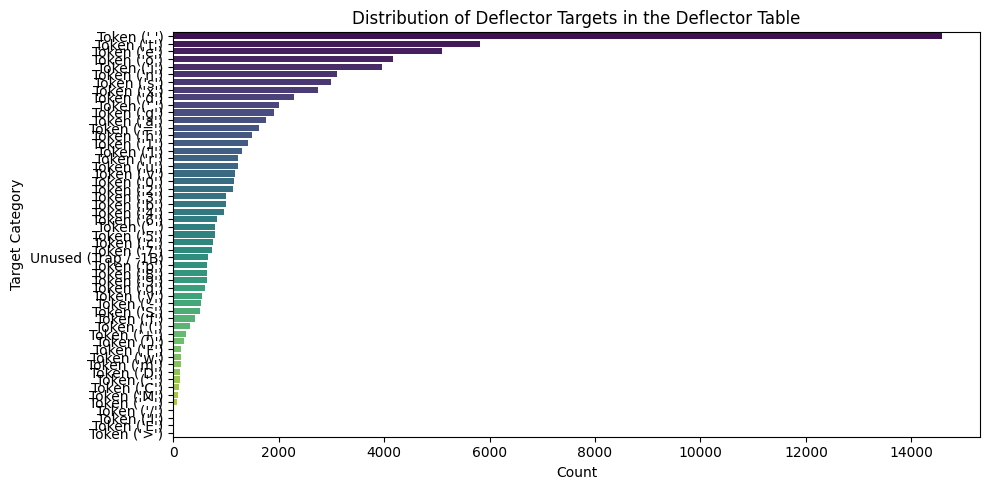

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extract deflectors details: [destination, value]
deflectors = brain.deflectors_list

# Separate into values: strings (emitted symbols) vs integers (bounce energy)
target_values = []
for dest, val in deflectors:
    if isinstance(val, int):
        if val < -1e6:
            target_values.append("Unused (Trap / -1B)")
        else:
            target_values.append(f"Int Bounce ({val})")
    else:
        target_values.append(f"Token ('{val}')")

df_targets = pd.DataFrame({'Target Category': target_values})
counts = df_targets['Target Category'].value_value_counts() if hasattr(df_targets['Target Category'], 'value_value_counts') else df_targets['Target Category'].value_counts()

# Plot distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=counts.values, y=counts.index, palette='viridis')
plt.title('Distribution of Deflector Targets in the Deflector Table')
plt.xlabel('Count')
plt.ylabel('Target Category')
plt.tight_layout()
plt.show()

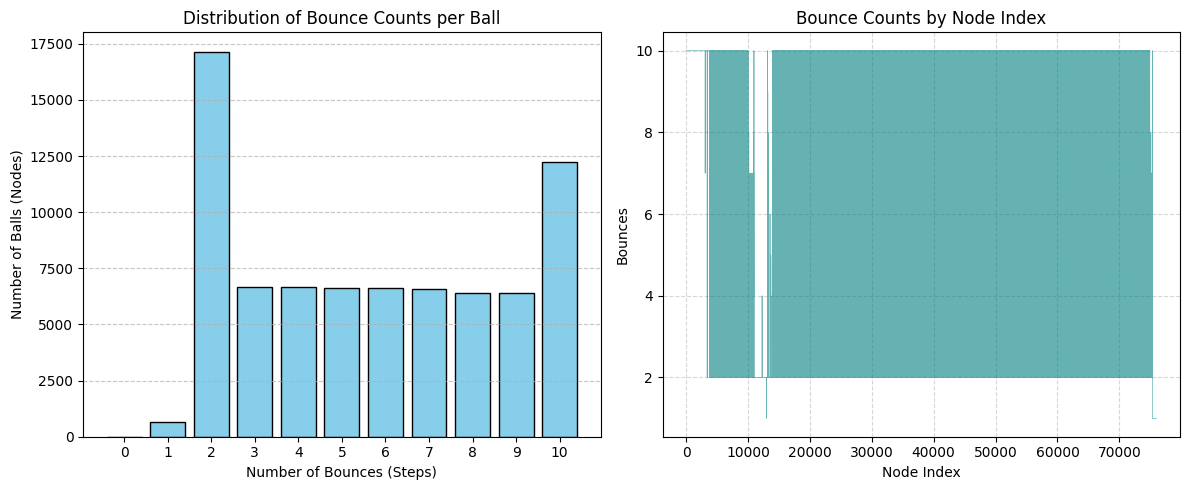

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# We will simulate a walk for each possible starting node (0 to D-1) and record the step count.
def get_bounce_counts(brain):
    step_counts = []
    dl = brain.deflectors_list
    cap = brain.cap

    for start_node in range(brain.D):
        be = brain.ball_energy
        node = start_node
        steps = 0

        while be > 0 and steps < cap:
            dest, val = dl[node]
            dist = abs(dest - node)
            if isinstance(val, int):
                be += val - dist
            else:
                be += 1 - dist
            node = dest
            steps += 1

        step_counts.append(steps)
    return step_counts

bounce_counts = get_bounce_counts(brain)

# Plot the results
plt.figure(figsize=(12, 5))

# Left subplot: Histogram of step distributions
plt.subplot(1, 2, 1)
plt.hist(bounce_counts, bins=np.arange(0, brain.cap + 2) - 0.5, rwidth=0.8, color='skyblue', edgecolor='black')
plt.title('Distribution of Bounce Counts per Ball')
plt.xlabel('Number of Bounces (Steps)')
plt.ylabel('Number of Balls (Nodes)')
plt.xticks(range(0, brain.cap + 1))
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Right subplot: Sequence plot across all D nodes
plt.subplot(1, 2, 2)
plt.plot(bounce_counts, color='teal', alpha=0.6, linewidth=0.5)
plt.title('Bounce Counts by Node Index')
plt.xlabel('Node Index')
plt.ylabel('Bounces')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Notes and limits

* **What changed.** The original global hash was an associative-memory address. The new
  address is a reusable local feature hash: the same `(relative position, token)` feature
  is shared across all examples, and each ball position has its own bucket region.
* **Why this can generalize.** A test context does not need to reproduce an entire training
  context. It only needs the relevant local features to land in buckets whose table entries
  were learned from other examples.
* **What did not change.** There is still exactly one lookup per ball. The walk never reads
  another input token after hashing, so this is not the proposed layered architecture.
* **Training objective.** Class purity / profiled CE remains primary. Reuse is only a
  tie-breaker, which prevents the optimizer from sacrificing fit merely to get more sharing.
* **Capacity knob.** `local_D` controls buckets per slot. Smaller values put more pressure
  on feature reuse; larger values make the search closer to memorization.
* **Locality knob.** `hash_radius` controls how much context a ball can use. Increasing it
  raises expressive power but weakens the inductive bias toward reuse.
